In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### **1. Create Corpus (tạo từ điển)**
Tạo danh sách từ vựng (vocabulary) bằng cách hoàn thiện hàm create_corpus để thu thập tất cả từ trong văn bản, loại các từ trùng nhau và sắp xếp từ điển

In [ ]:
def create_corpus(docs):
    """Tạo corpus từ danh sách văn bản"""
    # Làm sạch các docs được đưa vào
    processed_docs = [preprocess(doc) for doc in docs]

    # Lấy vocabulary => uniqueness
    vocabulary = sorted(set(word for doc in processed_docs for word in doc))

    return processed_docs, vocabulary

def preprocess(text):
    text = text.lower()  # Chuyển về chữ thường
    words = text.split()  # Tách từ
    return words

### **2. Term Frequency (TF)**
Tính TF (Term Frequency) bằng cách sử dụng thư viện Numpy để hoàn thiện

In [ ]:
def compute_tf(word_list, vocabulary):
    """Tính TF (Term Frequency)"""
    word_count = {}

    for word in word_list:
        word_count[word] = word_count.get(word, 0) + 1

    tf_vector = np.array([word_count[word] / len(word_list) if word in word_count else 0 for word in vocabulary])

    return tf_vector

### **3. Inverse Document Frequency**
Tính IDF (Inverse Document Frequency) dùng np.log

In [ ]:
def compute_idf(docs, vocabulary):
    """Tính IDF (Inverse Document Frequency)"""
    num_docs = len(docs)
    idf_vector = np.array([
        np.log((num_docs + 1) / (1 + sum(1 for doc in docs if word in doc))) + 1 for word in vocabulary
    ])
    return idf_vector

### **4. TF-IDF**
Tính TF-IDF

In [ ]:
def compute_tf_idf(docs):
    """Tính ma trận TF-IDF"""
    # Tạo corpus
    processed_docs, vocabulary = create_corpus(docs)

    # Tính TF và IDF
    tf_matrix = np.array([compute_tf(doc, vocabulary) for doc in processed_docs])
    idf_vector = compute_idf(processed_docs, vocabulary)

    # Tính TF-IDF
    tf_idf_matrix = tf_matrix * idf_vector
    # Nhân từng phần tử theo chiều dọc
    return tf_idf_matrix

### **5. Cosine Similarity**
Tính độ tương đồng Cosine Similarity

In [ ]:
def cosine_similarity(vec1, vec2):
    """Tính độ tương đồng cosine giữa hai vector"""
    dot_product = np.dot(vec1, vec2)
    norm1 = np.linalg.norm(vec1)
    norm2 = np.linalg.norm(vec2)

    return dot_product / (norm1 * norm2) if norm1 * norm2 != 0 else 0

### **6. Ứng dụng Correlation trong việc check đạo văn**
Tạo heatmap để hiển thị giá trị số trong ô: trực quan hóa ma trận độ tương đồng similarity_matrix giữa các văn bản bằng thư viện
seaborn. Hãy chọn dòng sns.heatmap(...) đúng để hiển thị cả giá trị số trong từng ô, dùng
định dạng 3 chữ số thập phân và bảng màu ’YlOrRd’.

In [ ]:
def check_plagiarism_all(docs):
    """Tính độ tương đồng giữa tất cả các cặp văn bản"""
    tf_idf_matrix = compute_tf_idf(docs)
    num_docs = len(docs)

    # Khởi tạo ma trận lưu chỉ số tương đồng
    similarity_matrix = np.zeros((num_docs, num_docs))

    for i in range(num_docs):
        for j in range(num_docs):
            similarity_matrix[i, j] = cosine_similarity(tf_idf_matrix[i], tf_idf_matrix[j])

    return similarity_matrix

# **Main**

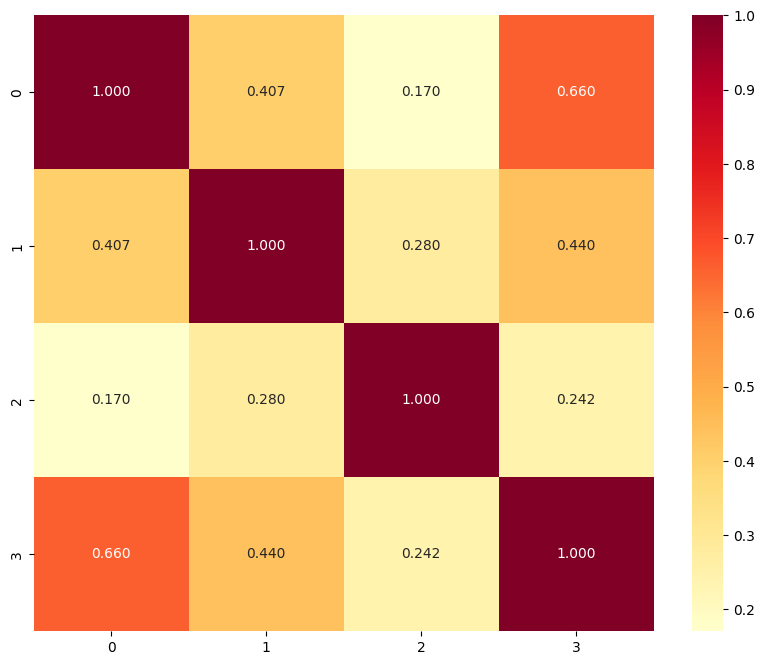

In [ ]:
docs = [
  "Học máy là một nhánh của trí tuệ nhân tạo",
  "Trí tuệ nhân tạo bao gồm học máy và mạng nơ ron",
  "Mạng nơ ron là một mô hình quan trọng trong học sâu",
  "Học sâu là một lĩnh vực của trí tuệ nhân tạo và học máy"
]

similarity_matrix = check_plagiarism_all(docs)

plt.figure(figsize=(10, 8))
sns.heatmap(similarity_matrix , annot =True , fmt=".3f", cmap ="YlOrRd")
plt.show()